In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="ee16pre"
# DATE = '20230430wp80_16pre'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee16pre 19520


  0%|          | 0/160 [00:00<?, ?it/s]

DY0


  1%|          | 1/160 [00:00<01:30,  1.75it/s]

DY1


...

 99%|█████████▉| 158/160 [00:52<00:00,  2.76it/s]

Zp-4100_CH-595


 99%|█████████▉| 159/160 [00:52<00:00,  2.77it/s]

Zp-4100_CH-845


100%|██████████| 160/160 [00:52<00:00,  3.03it/s]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))
TTUp_concat, TTDown_concat, TThdampUp_concat, TThdampDown_concat = ([] for i in range(4)) 
TTUp_concat_met_u, TTDown_concat_met_u, TThdampUp_concat_met_u, TThdampDown_concat_met_u = ([] for i in range(4)) 
TTUp_concat_met_d, TTDown_concat_met_d, TThdampUp_concat_met_d, TThdampDown_concat_met_d = ([] for i in range(4)) 

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))
TTUp_nevts, TTDown_nevts, TThdampUp_nevts, TThdampDown_nevts = ([] for i in range(4))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY1?'):
#         print(key)
#         print(dic_tup[key][0])
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT1?'):
#         print("TT", key)
#         print(dic_tup[key][0])
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampUp?') or fnmatch.fnmatch(key, 'TThdampUp1?'):
#         print(key)
#         print(dic_tup[key][0])
        TThdampUp_concat.append(dic_tup[key][1])
        TThdampUp_concat_met_u.append(dic_tup[key][2])
        TThdampUp_concat_met_d.append(dic_tup[key][3])
        TThdampUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampDown?') or fnmatch.fnmatch(key, 'TThdampDown1?'):
#         print(key)
#         print(dic_tup[key][0])
        TThdampDown_concat.append(dic_tup[key][1])
        TThdampDown_concat_met_u.append(dic_tup[key][2])
        TThdampDown_concat_met_d.append(dic_tup[key][3])
        TThdampDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTUp?') or fnmatch.fnmatch(key, 'TTUp1?'):
#         print(key)
#         print(dic_tup[key][0])
        TTUp_concat.append(dic_tup[key][1])
        TTUp_concat_met_u.append(dic_tup[key][2])
        TTUp_concat_met_d.append(dic_tup[key][3])
        TTUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTDown?') or fnmatch.fnmatch(key, 'TTDown1?'):
#         print(key)
#         print(dic_tup[key][0])
        TTDown_concat.append(dic_tup[key][1])
        TTDown_concat_met_u.append(dic_tup[key][2])
        TTDown_concat_met_d.append(dic_tup[key][3])
        TTDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
#         print(key)
#         print(dic_tup[key][0])
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
#         print(key)
#         print(dic_tup[key][0])
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
#         print(key)
#         print(dic_tup[key][0])
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
#         print(key)
#         print(dic_tup[key][0])
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
#         print("high", key)

In [8]:
# free memory 
dic_tup.clear()

In [9]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampUp']=sum(TThdampUp_nevts), pd.concat(TThdampUp_concat), pd.concat(TThdampUp_concat_met_u), pd.concat(TThdampUp_concat_met_d)
    tmp = "TThdampUp: "+str(sum(TThdampUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampDown']=sum(TThdampDown_nevts), pd.concat(TThdampDown_concat), pd.concat(TThdampDown_concat_met_u), pd.concat(TThdampDown_concat_met_d)
    tmp = "TThdampDown: "+str(sum(TThdampDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTUp']=sum(TTUp_nevts), pd.concat(TTUp_concat), pd.concat(TTUp_concat_met_u), pd.concat(TTUp_concat_met_d)
    tmp = "TTUp: "+str(sum(TTUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTDown']=sum(TTDown_nevts), pd.concat(TTDown_concat), pd.concat(TTDown_concat_met_u), pd.concat(TTDown_concat_met_d)
    tmp = "TTDown: "+str(sum(TTDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 37202074
TThdampUp: 14800956
TThdampDown: 16693362
TTUp: 10296740
TTDown: 21408998
TTSemi: 131106830
TTZ: 2856626
DY: 61189340
top: 2299880
antitop: 2299866
ZZ: 16826232
WZ: 16136161
WW: 3006596
Data: 652566543


In [10]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [11]:
print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts))

# try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#    beep()
#    print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
#    raise

expected: 652566543 , while:  652566543


In [12]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [13]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key)  
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df[key]["weighthdampUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weighthdampDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.008667758155804407
DY1000To15001
DY1000To1500 : 0.007795036700454387
DY1000To15002
DY1000To1500 : 0.01653501390176089
DY1000To15003
DY1000To1500 : 0.1624888888888889
DY1500To20000
DY1500To2000 : 0.0004082729369350264
DY2000To30000
DY2000To3000 : 0.00011616005280818526
DY2000To30001
DY2000To3000 : 0.0005063236944324557
DY500To7000
DY500To700 : 0.03152063934954012
DY700To8000
DY700To800 : 0.02483678917072554
DY700To8001
DY700To800 : 0.00957109984399376
DY800To10000
DY800To1000 : 0.005964288790010047
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009169194666666665
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009169194666666665
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009169194666666665
Zp-2100_CH-345
Zp-2100_CH-345 : 0.0031179946666666665
Zp-2100_CH-595
Zp-2100_CH-595 : 0.0031179946666666665
Zp-2100_CH-845
Zp-2100_CH-845 : 0.0031179946666666665
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0011441322666666666
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0011441322666666666
Zp-2500_CH-845
Zp-2500_CH-845 : 0.001

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [15]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 14 ( 1.3173391744494438 )
DY1000To1500 (met_u) : 15
DY1000To1500 (met_d) : 14
DY1500To2000 : 845 ( 0.1807587227945537 )
DY1500To2000 (met_u) : 884
DY1500To2000 (met_d) : 811
DY2000To3000 : 206 ( 0.04953425406711176 )
DY2000To3000 (met_u) : 214
DY2000To3000 (met_d) : 202
DY500To700 : 255 ( 4.040207279858379 )
DY500To700 (met_u) : 272
DY500To700 (met_d) : 241
DY700To800 : 221 ( 0.8140678087440598 )
DY700To800 (met_u) : 231
DY700To800 (met_d) : 211
DY800To1000 : 411 ( 1.0983699701472518 )
DY800To1000 (met_u) : 443
DY800To1000 (met_d) : 392
Zp-1700_CH-345 : 3925 ( 33.151165410876274 )
Zp-1700_CH-345 (met_u) : 3941
Zp-1700_CH-345 (met_d) : 3915
Zp-1700_CH-595 : 4677 ( 39.55057624098845 )
Zp-1700_CH-595 (met_u) : 4684
Zp-1700_CH-595 (met_d) : 4680
Zp-1700_CH-845 : 5258 ( 44.55658150045201 )
Zp-1700_CH-845 (met_u) : 5268
Zp-1700_CH-845 (met_d) : 5257
Zp-2100_CH-345 : 4516 ( 13.045272044837475 )
Zp-2100_CH-345 (met_u) : 4524
Zp-2100_CH-345 (met_d) : 4514
Zp-2100_CH-595 : 5418 ( 

In [16]:
dic_df_raw["TT"]["topSF_pre"]

15       0.939860
16       0.972836
18       0.935827
27       0.986938
28       0.958303
           ...   
27709    0.985942
27715    0.926292
27728    0.927855
27735    0.982490
27747    0.953707
Name: topSF_pre, Length: 64829, dtype: float32

In [17]:
dic_df_raw["TThdampUp"]["topSF_pre"]

5        0.898099
9        0.942666
17       0.926611
22       0.923346
24       0.958245
           ...   
10703    0.997179
10709    0.910561
10710    0.955807
10715    0.956847
10718    0.965908
Name: topSF_pre, Length: 24919, dtype: float32

In [18]:
dic_df_raw["TTZ"]["topSF_pre"]

12       1.0
37       1.0
43       1.0
45       1.0
59       1.0
        ... 
44978    1.0
45094    1.0
45125    1.0
45149    1.0
45157    1.0
Name: topSF_pre, Length: 6142, dtype: float32

In [19]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [20]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [21]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
    "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [14, 0, 660, "U [GeV]"],
    "JZB_pre": [14, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
    "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]']}
[('PuppiMET_pre', [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'])]


In [22]:
SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "trigSF", "hdamp", "PS"]
# SYS_LIST = ["hdamp", "PS"]

In [23]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
sys_list = SYS_LIST
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    """
        draw histograms with sys variations, return sys uncertainty dic
    """
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable and "PuppiMET_phi_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
#         sys_list = ["hdamp", "PS"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [24]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
#         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET_pre" in variable:
            threshold = 0.5
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([5.04968744e+02, 5.27791309e+01, 6.48100465e+00, 2.83385326e+00,
       3.24477079e-02, 7.20718446e-01, 5.25371698e-02, 1.55686392e-01,
       1.88167130e-03, 1.02779486e-05, 9.27791887e-04, 3.18837963e-04,
       1.84100843e-06, 5.55962429e-05, 4.96152512e-04]), 'puweightDown': array([6.66095488e+02, 6.45167554e+01, 3.87472194e+00, 2.89718435e+00,
       2.77413536e-02, 6.00310969e-01, 2.30483408e-02, 1.21155715e-01,
       3.12670996e-03, 2.98220529e-04, 1.03701593e-03, 3.35057147e-04,
       0.00000000e+00, 6.97056632e-05, 2.66065498e-04]), 'l1prefiringUp': array([8.55243898e+01, 1.82080869e+01, 2.76471620e+00, 1.56605005e-01,
       2.49895502e-02, 5.08579366e-03, 4.67366492e-04, 9.01014109e-06,
       4.21133298e-05, 1.14444945e-05, 1.97812993e-04, 1.69663397e-07,
       2.05128955e-06, 3.15847180e-08, 7.07967986e-07]), 'l1prefiringDown': array([9.13346631e+01, 1.92720186e+01, 2.86760434e+00, 1.67876161e-01,
       2.64716111e-02, 5.47381288e-03, 5.02443735e-0

       1.41746642e-01, 7.52720957e-02, 6.05919873e-02])}
{'puweightUp': array([3.04782047e+01, 1.18457877e+02, 5.07535044e+01, 1.71835209e+01,
       1.37877521e+01, 3.81127153e+00, 2.10697757e+00, 2.96860511e-01,
       6.29783629e-01, 4.25597939e-01, 8.18263969e-02, 2.46424944e-02,
       2.53741542e-03, 5.02875274e-03, 9.88225825e-03, 2.94320592e-05,
       9.93116968e-03, 5.55067716e-02, 1.09517684e-04, 2.40968844e-04,
       1.91096651e-03, 3.31010915e-03]), 'puweightDown': array([4.21649706e+01, 1.48060089e+02, 5.87487110e+01, 2.03437247e+01,
       1.83642731e+01, 5.18173996e+00, 1.70121333e-01, 4.29603767e-01,
       6.93111715e-01, 5.21388509e-01, 1.04352878e-01, 3.42865773e-02,
       7.40769959e-03, 1.21042214e-02, 1.65337020e-02, 3.10321961e-06,
       1.05178455e-02, 2.29677713e-02, 6.83287417e-04, 3.04558233e-04,
       2.95884911e-03, 3.91136720e-03]), 'l1prefiringUp': array([6.75311718e+00, 1.35224009e+01, 9.22155956e+00, 4.09807385e+00,
       1.77505645e+00, 9.0461931

        0.06936497,  0.17673043])}
{'puweightUp': array([4.02444629e+02, 8.07269856e+01, 9.94252096e+00, 1.72071727e+00,
       1.03594592e+00, 1.12510233e-01, 2.69776508e-02, 2.91951156e-03,
       1.83026922e-07, 1.06344357e-04, 3.36908405e-03, 2.26036366e-06,
       1.73044801e-03, 4.27645543e-04]), 'puweightDown': array([4.73765887e+02, 1.03837859e+02, 1.12322929e+01, 2.01709808e+00,
       1.11050878e+00, 1.24762825e-01, 3.06099194e-02, 8.44513489e-03,
       6.07939773e-05, 2.90474471e-04, 3.50882289e-03, 1.87773073e-04,
       1.86119535e-03, 8.28131284e-04]), 'l1prefiringUp': array([8.46349634e+01, 1.31195229e+01, 2.35078028e+00, 5.16853673e-01,
       1.14645665e-01, 6.40394502e-02, 4.71234351e-03, 2.98383823e-03,
       9.12020055e-04, 5.77005142e-05, 4.31917207e-05, 5.22907886e-05,
       4.59346855e-05, 4.98420650e-05]), 'l1prefiringDown': array([9.03637632e+01, 1.38668810e+01, 2.47359908e+00, 5.42878691e-01,
       1.19578050e-01, 6.63800350e-02, 5.13310297e-03, 3.16020224

         0.29884579,   0.27760605])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([3.31328117e+02, 1.17804366e+02, 1.34071905e+00, 4.68498623e+00,
       9.15109810e-01, 1.29893070e+00, 1.86027050e-03, 8.64782331e-01,
       0.00000000e+00, 9.48453826e-02, 4.77313467e-05, 3.52276749e-03,
       8.56206375e-05, 1.51202477e-03, 2.52619086e-03]), 'puweightDown': array([3.97583116e+02, 1.52752483e+02, 3.53541998e-01, 6.41884386e+00,
       1.46438104e+00, 1.37476401e+00, 1.81521496e-02, 7.77793033e-01,
       5.61531455e-04, 5

       2.15636511e-02, 4.05570730e-01, 1.49389017e-01])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [4.390909671783447, 4.866497039794922, 10.618252754211426, 117.42652893066406, 263.6268310546875, 2537.29296875, 2473.353515625, 2512.2939453125, 2546.942138671875, 2552.36474609375, 100.35910034179688, 5.417418956756592])
test


Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf

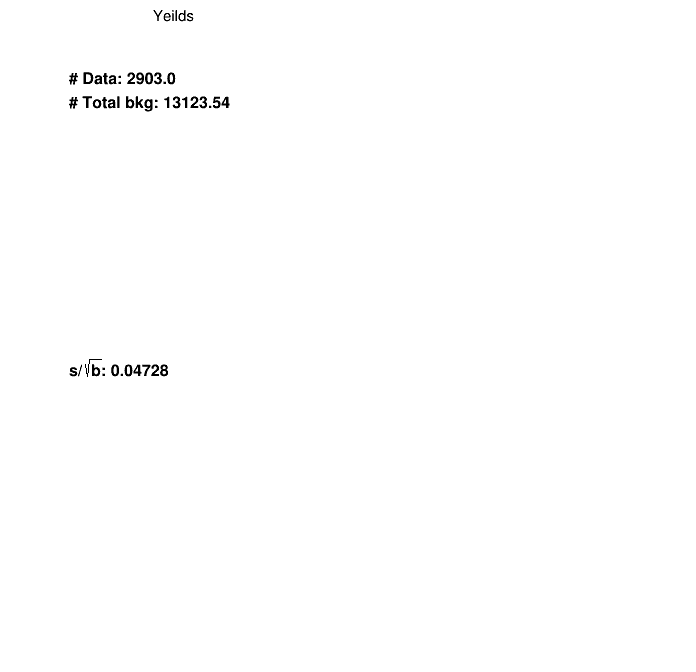

In [25]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

array('f', [4.390909671783447, 4.866497039794922, 10.618252754211426, 117.42652893066406, 263.6268310546875, 2665.012939453125, 2597.55126953125, 2638.5625, 2674.380859375, 2681.011962890625, 100.35910034179688, 5.417418956756592])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanv

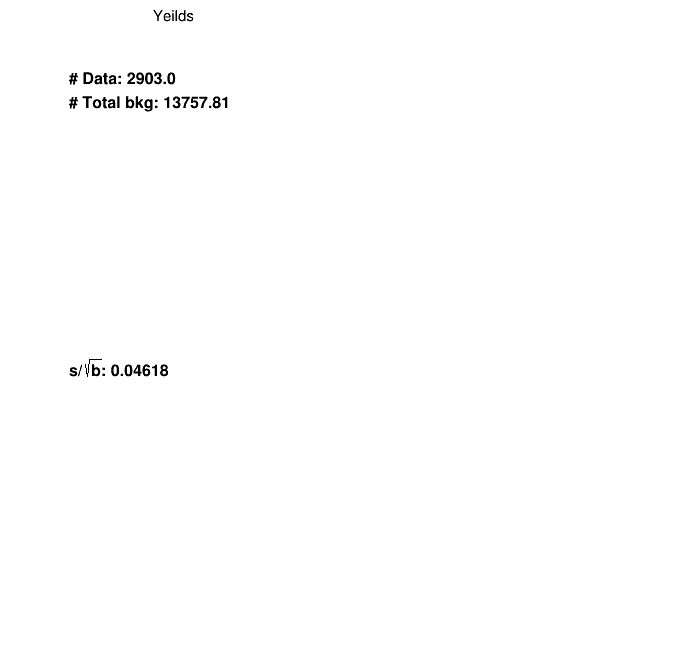

In [26]:
###### wotop ######
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
}
os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

for variable, r in dic_variable.items():
    if not "Puppi" in variable:
        threshold = 0.3
    else:
        threshold = 0.5
    hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
    hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
hist.get_yeilds()
hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [27]:
dic_df_raw["TT"]["trigSF_pre"]

15       1.001046
16       0.997926
18       1.000533
27       0.992304
28       0.953071
           ...   
27709    1.001608
27715    0.998573
27728    1.002751
27735    0.983134
27747    0.998772
Name: trigSF_pre, Length: 64829, dtype: float32

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/SR/sig_eff.pdf has been created


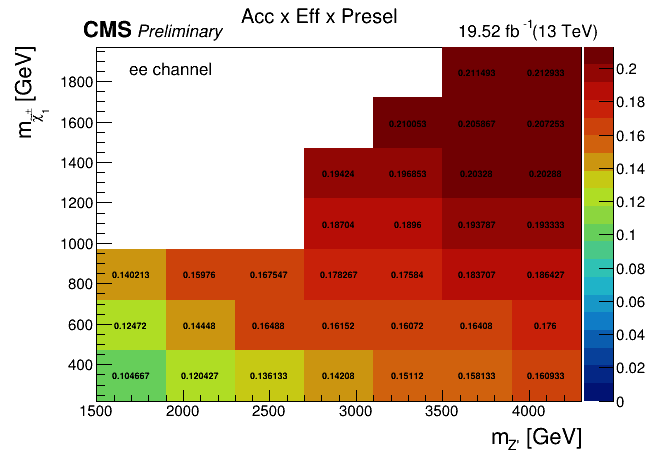

In [28]:
str_channel, str_lumi = HistStack.get_str_lumi_channel(ERA, ERA)

Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz text")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+str_channel+" channel}}")

latex1=rt.TLatex()
latex1.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
latex1.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
 
c1.Draw()
c1.SaveAs(DATE+"/Presel/"+ERA+"/"+region+"/sig_eff.pdf")

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 6
DY1500To2000 : 315
DY2000To3000 : 69
DY500To700 : 270
DY700To800 : 162
DY800To1000 : 285
Zp-1700_CH-345 : 593
Zp-1700_CH-595 : 416
Zp-1700_CH-845 : 334
Zp-2100_CH-345 : 495
Zp-2100_CH-595 : 380
Zp-2100_CH-845 : 307
Zp-2500_CH-345 : 517
Zp-2500_CH-595 : 409
Zp-2500_CH-845 : 287
Zp-2900_CH-1095 : 212
Zp-2900_CH-1345 : 176
Zp-2900_CH-345 : 423
Zp-2900_CH-595 : 372
Zp-2900_CH-845 : 283
Zp-3300_CH-1095 : 205
Zp-3300_CH-1345 : 154
Zp-3300_CH-1595 : 166
Zp-3300_CH-345 : 405
Zp-3300_CH-595 : 308
Zp-3300_CH-845 : 266
Zp-3700_CH-1095 : 237
Zp-3700_CH-1345 : 162
Zp-3700_CH-1595 : 130
Zp-3700_CH-1845 : 124
Zp-3700_CH-345 : 368
Zp-3700_CH-595 : 303
Zp-3700_CH-845 : 266
Zp-4100_CH-1095 : 197
Zp-4100_CH-1345 : 140
Zp-4100_CH-1595 : 142
Zp-4100_CH-1845 : 117
Zp-4100_CH-345 : 344
Zp-4100_CH-595 : 294
Zp-4100_CH-845 : 254
TT : 351

       7.12213886e-04, 2.63057416e-02])}
here {'puweightUp': array([5.57100064e+00, 2.36826990e+01, 1.30750748e+00, 9.06958411e+00,
       6.36878392e-01, 2.19073586e-01, 8.14350353e-02, 1.71538005e+00,
       2.75536860e-02, 0.00000000e+00, 1.48789885e-02, 1.41190196e-01,
       1.46238314e-03, 3.25545449e-07, 1.34387095e-03, 1.09529136e-03,
       6.63145791e-04, 8.19034163e-05, 8.10869238e-04, 9.90534870e-09,
       3.07177159e-04, 2.49016500e-03, 4.28860913e-05, 1.51991324e-03,
       3.06541822e-04, 1.62288454e-06, 1.16660245e-06, 3.65030975e-05,
       1.59485417e-07, 6.65827957e-04]), 'puweightDown': array([7.99219443e-01, 2.67727768e+01, 3.59076700e+00, 1.17648053e+01,
       7.36608924e-01, 3.47822522e-01, 1.00348878e-01, 1.84853526e+00,
       7.13078140e-02, 9.23705090e-04, 1.74130087e-02, 1.47359544e-01,
       2.41169207e-03, 4.59042179e-05, 4.80445255e-04, 6.72284175e-04,
       5.97857764e-04, 1.54195215e-04, 5.37936792e-04, 7.29285263e-06,
       2.95656619e-04, 3.74687

       7.12213886e-04, 2.63057416e-02])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([5.12679476e+00, 3.34211264e+00, 2.19051105e+01, 5.74239494e+00,
       6.48195067e+00, 2.71014029e-02, 3.86156648e-01, 6.03547341e-01,
       4.20477024e-02, 1.39239450e+00, 6.22482371e-01, 1.71315974e-02,
       8.41349124e-02, 6.98922673e-01, 3.06900971e-03, 6.21981832e-03,
       1.51371860e-04, 3.26190603e-02, 2.67380894e-04, 0.00000000e+00,
       5.71434754e-05, 4.17026151e-06, 2.84367108e-04, 2.00955921e-04,
       1.00253252e-05, 5.16883190e-04, 9.40450065e-07, 1.45620550e-05,
       2.91694737e-07, 1.21498296e-04, 1.23969802e-03]), 'puweightDown': array([2.65829068e+00, 7.37686281e+00, 2.36058649e+01, 7.39109439e+00,
       2.95227498e+00, 1.23570655e-01, 7.98604977e-01, 

       1.65997932e-02, 1.03024444e-02, 3.80348846e-02])}
here {'puweightUp': array([5.12679476e+00, 3.34211264e+00, 2.19051105e+01, 5.74239494e+00,
       6.48195067e+00, 2.71014029e-02, 3.86156648e-01, 6.03547341e-01,
       4.20477024e-02, 1.39239450e+00, 6.22482371e-01, 1.71315974e-02,
       8.41349124e-02, 6.98922673e-01, 3.06900971e-03, 6.21981832e-03,
       1.51371860e-04, 3.26190603e-02, 2.67380894e-04, 0.00000000e+00,
       5.71434754e-05, 4.17026151e-06, 2.84367108e-04, 2.00955921e-04,
       1.00253252e-05, 5.16883190e-04, 9.40450065e-07, 1.45620550e-05,
       2.91694737e-07, 1.21498296e-04, 1.23969802e-03]), 'puweightDown': array([2.65829068e+00, 7.37686281e+00, 2.36058649e+01, 7.39109439e+00,
       2.95227498e+00, 1.23570655e-01, 7.98604977e-01, 6.00532360e-01,
       8.20359167e-02, 1.47327173e+00, 5.77663786e-01, 1.93711889e-02,
       7.27143942e-02, 5.81108052e-01, 4.39191937e-03, 7.36390154e-03,
       5.35663394e-04, 3.38000189e-02, 4.58479210e-04, 6.69619589e-05

       1.65997932e-02, 1.03024444e-02, 3.80348846e-02])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , 29.77526317, 10.20269452,  0.37626158, 20.41249172]), 'puweightDown': array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        , 31.56370365, 10.10706001,  0.40671408, 22.86639628]), 'l1prefiringUp': array([0.        , 0.        , 0.        , 0.        , 0.        ,


        0.        , 21.25463026, 19.38721164, 34.40446242, 18.85934441])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [1.4181872606277466, 1.428971290588379, 5.934500694274902, 70.18304443359375, 139.6707000732422, 1403.108154296875, 1367.2799072265625, 1398.923828125, 1392.95849609375, 1416.29736328125, 140.48025512695312, 0.5447093844413757])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and 

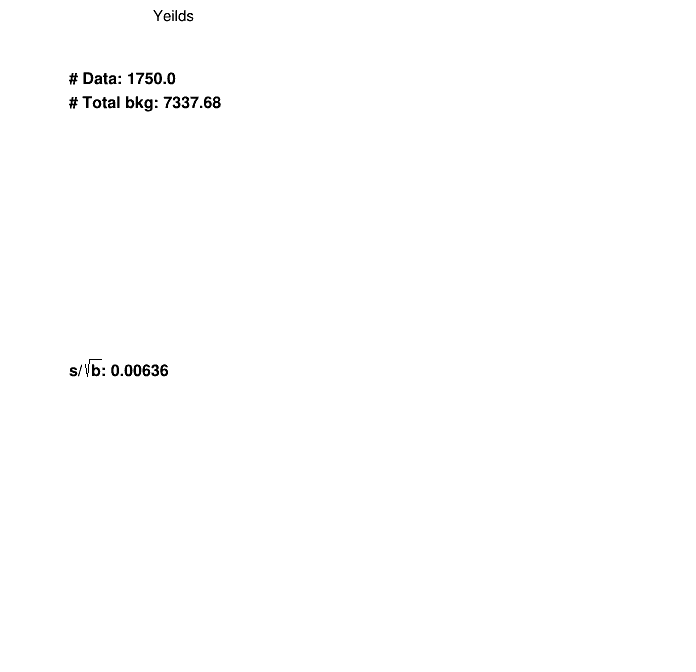

In [29]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [30]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [31]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
#     sys_list = ["puweight", "l1prefiring", "effSF", "topSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 0
DY2000To3000 : 0
DY500To700 : 0
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 10
Zp-1700_CH-595 : 168
Zp-1700_CH-845 : 450
Zp-2100_CH-345 : 2
Zp-2100_CH-595 : 72
Zp-2100_CH-845 : 249
Zp-2500_CH-345 : 0
Zp-2500_CH-595 : 42
Zp-2500_CH-845 : 127
Zp-2900_CH-1095 : 142
Zp-2900_CH-1345 : 224
Zp-2900_CH-345 : 3
Zp-2900_CH-595 : 16
Zp-2900_CH-845 : 75
Zp-3300_CH-1095 : 117
Zp-3300_CH-1345 : 130
Zp-3300_CH-1595 : 157
Zp-3300_CH-345 : 2
Zp-3300_CH-595 : 6
Zp-3300_CH-845 : 57
Zp-3700_CH-1095 : 59
Zp-3700_CH-1345 : 85
Zp-3700_CH-1595 : 115
Zp-3700_CH-1845 : 164
Zp-3700_CH-345 : 2
Zp-3700_CH-595 : 5
Zp-3700_CH-845 : 31
Zp-4100_CH-1095 : 47
Zp-4100_CH-1345 : 69
Zp-4100_CH-1595 : 77
Zp-4100_CH-1845 : 112
Zp-4100_CH-345 : 0
Zp-4100_CH-595 : 2
Zp-4100_CH-845 : 18
TT : 3062
TThdampUp : 1257
TThdampDown : 1295
TT

       0.00000000e+00, 0.00000000e+00])}
 here{'puweightUp': array([2.35892292e+02, 1.81710347e+02, 2.82328403e+01, 1.35977204e+01,
       8.74378966e-01, 1.70941674e-03, 4.51636148e-01, 5.04349439e-01,
       2.53646411e-02, 5.35424516e-01, 1.59255350e-02, 1.03952763e-02,
       1.54212295e-02, 2.96332475e-02, 0.00000000e+00, 2.42272181e-06,
       3.40835067e-09, 1.49192757e-06, 1.62932106e-08, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 6.09266161e-09, 0.00000000e+00,
       6.60198872e-07, 7.79301889e-09, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([1.62815479e+02, 8.44254893e+01, 4.14743361e+00, 1.60735521e+01,
       2.90283593e-01, 1.24699662e-02, 5.39282039e-01, 5.34271886e-01,
       4.78563596e-02, 4.79958630e-01, 1.85943496e-02, 8.49690131e-03,
       3.85799279e-02, 4.56180165e-02, 9.78384329e-04, 3.37969872e-06,
       0.00000000e+00, 1.30983718e-06, 1.00187651e-07, 0.00000000e+00,
       0.00000000e+00, 0.00000

       0.00000000e+00, 0.00000000e+00])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([6.80729268e+00, 3.00481701e+02, 5.62841637e+00, 4.57721357e+00,
       2.79253959e+00, 1.32689431e-01, 8.43978709e-01, 2.28531713e+01,
       1.64876148e-01, 1.94449333e+00, 1.41412262e-01, 9.95695385e-02,
       5.84995270e-02, 1.75266948e+00, 4.88391827e-01, 9.68075178e-02,
       3.49268799e-01, 1.00973570e-03, 8.64462632e-02, 7.15242039e-03,
       9.68312488e-03, 2.22711115e-01, 5.47067947e-02, 1.86715038e-02,
       1.01020632e-05, 7.11372705e-07, 6.75935661e-04, 3.85032551e-03,
       3.08467577e-06, 2.81499909e-06, 0.00000000e+00]), 'puweightDown': array([1.23799229e+01, 1.20388101e+02, 7.87865927e+00, 2.57683191e+00,
       3.09555643e+00, 4.28101282e-01, 2.96496499e-01, 

       6.22715280e-03, 5.64353412e-03, 7.50586283e-03])}
here {'puweightUp': array([6.80729268e+00, 3.00481701e+02, 5.62841637e+00, 4.57721357e+00,
       2.79253959e+00, 1.32689431e-01, 8.43978709e-01, 2.28531713e+01,
       1.64876148e-01, 1.94449333e+00, 1.41412262e-01, 9.95695385e-02,
       5.84995270e-02, 1.75266948e+00, 4.88391827e-01, 9.68075178e-02,
       3.49268799e-01, 1.00973570e-03, 8.64462632e-02, 7.15242039e-03,
       9.68312488e-03, 2.22711115e-01, 5.47067947e-02, 1.86715038e-02,
       1.01020632e-05, 7.11372705e-07, 6.75935661e-04, 3.85032551e-03,
       3.08467577e-06, 2.81499909e-06, 0.00000000e+00]), 'puweightDown': array([1.23799229e+01, 1.20388101e+02, 7.87865927e+00, 2.57683191e+00,
       3.09555643e+00, 4.28101282e-01, 2.96496499e-01, 1.44827862e-01,
       9.44295236e-02, 1.91005022e+00, 3.09618950e-01, 1.30574847e-01,
       8.65882911e-02, 2.44016936e+00, 3.51867976e-01, 2.26071197e-02,
       2.76507200e-01, 3.97942270e-03, 1.06848721e-01, 9.13050465e-03

       6.22715280e-03, 5.64353412e-03, 7.50586283e-03])}
{'puweightUp': array([1036.41282056]), 'puweightDown': array([476.70808483]), 'l1prefiringUp': array([4.7449461]), 'l1prefiringDown': array([4.86836658]), 'effSFUp': array([355.11841893]), 'effSFDown': array([335.42432652]), 'topSFUp': array([6.03719256]), 'topSFDown': array([0.]), 'metUp': array([996.18975015]), 'metDown': array([686.97066706]), 'trigSFUp': array([4.01194677]), 'trigSFDown': array([4.82475347]), 'hdampUp': array([2.12017264]), 'hdampDown': array([24.87849688]), 'PSUp': array([0.00049603]), 'PSDown': array([58.8717386]), 'sum_up': array([49.03708539]), 'sum_down': array([39.90672166])}
here {'puweightUp': array([1036.41282056]), 'puweightDown': array([476.70808483]), 'l1prefiringUp': array([4.7449461]), 'l1prefiringDown': array([4.86836658]), 'effSFUp': array([355.11841893]), 'effSFDown': array([335.42432652]), 'topSFUp': array([6.03719256]), 'topSFDown': array([0.]), 'metUp': array([996.18975015]), 'metDown': ar

       6.47050501e-03, 5.11253482e-02, 9.70264284e-04, 2.11936209e-02])}
here {'puweightUp': array([1.80370981e+02, 3.38751721e+02, 7.72891195e-02, 1.73118403e-04,
       1.52183056e-03, 2.74112636e-02, 3.19549170e-02, 1.46611332e-01,
       1.49674951e-02, 4.33136821e-03, 1.15553147e-03, 4.09018011e-02,
       4.04478654e-03, 3.34623517e-03, 9.75140167e-04, 1.72444193e-03,
       1.44134186e-03, 7.05356869e-06, 9.69859999e-05, 1.03887228e-06,
       0.00000000e+00, 7.69867767e-04, 7.77650043e-05, 5.97169227e-03,
       1.58576373e-05, 1.35128567e-05, 5.54181484e-07, 3.16804216e-04]), 'puweightDown': array([2.12622821e+02, 4.35966510e+01, 4.63425998e-01, 8.30665747e-03,
       4.23731616e-03, 9.01101237e-02, 4.34668888e-02, 2.35298522e-01,
       1.46832789e-02, 7.40698909e-03, 1.19110564e-03, 4.54080617e-02,
       3.91758098e-03, 4.99949996e-04, 4.42206723e-05, 1.59528749e-03,
       9.55419434e-04, 8.35322557e-05, 1.64673735e-04, 1.15876969e-05,
       8.99066570e-05, 5.29897977e-04

       6.47050501e-03, 5.11253482e-02, 9.70264284e-04, 2.11936209e-02])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [10.540047645568848, 32.18274688720703, 38.841705322265625, 9.827940940856934, 13.515048027038574, 123.5153579711914, 128.41990661621094, 116.03553771972656, 115.1073455810

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230430wp80_16pre/Presel/ee16pre/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_tra

In [32]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 42
DY2000To3000 : 5
DY500To700 : 38
DY700To800 : 36
DY800To1000 : 38
Zp-1700_CH-345 : 529
Zp-1700_CH-595 : 441
Zp-1700_CH-845 : 337
Zp-2100_CH-345 : 495
Zp-2100_CH-595 : 460
Zp-2100_CH-845 : 337
Zp-2500_CH-345 : 488
Zp-2500_CH-595 : 426
Zp-2500_CH-845 : 351
Zp-2900_CH-1095 : 258
Zp-2900_CH-1345 : 224
Zp-2900_CH-345 : 429
Zp-2900_CH-595 : 404
Zp-2900_CH-845 : 373
Zp-3300_CH-1095 : 268
Zp-3300_CH-1345 : 178
Zp-3300_CH-1595 : 180
Zp-3300_CH-345 : 371
Zp-3300_CH-595 : 402
Zp-3300_CH-845 : 315
Zp-3700_CH-1095 : 242
Zp-3700_CH-1345 : 190
Zp-3700_CH-1595 : 208
Zp-3700_CH-1845 : 174
Zp-3700_CH-345 : 363
Zp-3700_CH-595 : 348
Zp-3700_CH-845 : 307
Zp-4100_CH-1095 : 235
Zp-4100_CH-1345 : 198
Zp-4100_CH-1595 : 178
Zp-4100_CH-1845 : 156
Zp-4100_CH-345 : 384
Zp-4100_CH-595 : 319
Zp-4100_CH-845 : 266
TT : 22337
TT

       6.54343146, 6.33363969, 3.09716148, 0.        , 0.        ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([0.00000000e+00, 7.50628766e-03, 2.20181859e-03, 1.81512557e-04,
       4.73675533e-01, 3.17577164e-01, 7.21121310e-01, 1.01869407e+00,
       6.06579888e-01, 1.06228188e+00, 3.36864246e+00, 2.93165723e+00,
       8.88263441e-01, 4.65332684e+00, 8.02978542e-01, 3.42265060e-01,
       4.94881394e-01, 2.69449372e-01, 1.87253503e-01, 2.03522092e-01,
       1.76942934e-01, 8.26864671e-02, 3.38682011e-03, 2.88050623e-03,
       1.13318127e-02, 5.04517888e-03, 6.04655437e-02]), 'puweightDown': array([0.00000000e+00, 6.61724894e-03, 0.00000000e+00, 1.46963902e-02,
       5.08195030e-01, 2.42011789e-01, 8.19200074e-01, 1.12296875e+00,
       7.57248750e-01, 1.51423031e+00, 4.2283744

       0.00000000e+00, 0.00000000e+00])}

herehere  {'puweightUp': array([0.00000000e+00, 7.50628766e-03, 2.20181859e-03, 1.81512557e-04,
       4.73675533e-01, 3.17577164e-01, 7.21121310e-01, 1.01869407e+00,
       6.06579888e-01, 1.06228188e+00, 3.36864246e+00, 2.93165723e+00,
       8.88263441e-01, 4.65332684e+00, 8.02978542e-01, 3.42265060e-01,
       4.94881394e-01, 2.69449372e-01, 1.87253503e-01, 2.03522092e-01,
       1.76942934e-01, 8.26864671e-02, 3.38682011e-03, 2.88050623e-03,
       1.13318127e-02, 5.04517888e-03, 6.04655437e-02]), 'puweightDown': array([0.00000000e+00, 6.61724894e-03, 0.00000000e+00, 1.46963902e-02,
       5.08195030e-01, 2.42011789e-01, 8.19200074e-01, 1.12296875e+00,
       7.57248750e-01, 1.51423031e+00, 4.22837447e+00, 3.87131516e+00,
       2.08056824e+00, 4.50492672e+00, 1.02334000e+00, 6.45421601e-01,
       6.74771033e-01, 2.55770224e-01, 2.21268269e-01, 1.85357719e-01,
       1.40819318e-01, 7.23325808e-02, 5.59167513e-03, 5.14327321e-03,
       1

       0.00000000e+00, 0.00000000e+00])}

{'puweightUp': array([8.82413757e-03, 5.67396263e-04, 1.62509754e-02, 2.83352365e-03,
       1.10706789e-01, 2.07677545e-02, 1.02515207e-01, 7.85412024e-01,
       4.27661889e-02, 1.46784902e+00, 4.05305136e+00, 9.11127920e+00,
       1.05590233e+01, 2.43588915e+00, 4.46694192e+00, 4.68507548e+00,
       0.00000000e+00]), 'puweightDown': array([8.95865943e-03, 1.24634543e-02, 3.64888704e-02, 1.64200488e-02,
       2.48913437e-01, 4.33462009e-02, 8.67170416e-02, 1.09589733e+00,
       1.52161598e-02, 1.80396087e+00, 5.07380638e+00, 1.06241230e+01,
       1.22631951e+01, 3.32718610e+00, 4.43983584e+00, 5.30057543e+00,
       0.00000000e+00]), 'l1prefiringUp': array([0.00621531, 0.01656903, 0.03828077, 0.01079244, 0.01164726,
       0.03015394, 0.04099205, 0.04445951, 0.18986927, 0.21305314,
       0.28465029, 0.29119399, 0.37735898, 0.35038089, 0.43822856,
       0.20528902, 0.        ]), 'l1prefiringDown': array([0.00666061, 0.01689688, 0.038892

       4.62006576, 0.        ])}
{'puweightUp': array([5.43232746e+01, 3.03375836e+01, 5.28604009e+00, 1.29898794e-01,
       5.85150187e-02, 1.52818053e-01, 9.34029737e-02, 9.14783147e-05,
       4.66241867e-05, 4.06465988e-03, 1.08479142e-04, 0.00000000e+00,
       7.91880514e-09, 1.73884425e-06, 0.00000000e+00]), 'puweightDown': array([7.53899779e+01, 3.53301369e+01, 4.36589814e+00, 2.30962917e-01,
       1.01249052e-01, 1.45558765e-01, 8.81566519e-02, 4.17116158e-04,
       4.55655715e-04, 5.62241135e-03, 3.65727629e-04, 3.29384963e-06,
       1.21504205e-06, 3.09329638e-06, 2.60723352e-06]), 'l1prefiringUp': array([1.01465101e+01, 1.84940776e+00, 2.66836268e-01, 4.46792735e-02,
       9.95076883e-03, 1.17929926e-03, 5.30021212e-04, 2.30312003e-05,
       4.41455496e-04, 1.19724869e-03, 2.60963751e-06, 9.09322225e-07,
       2.17127809e-08, 1.11425592e-09, 6.57935753e-08]), 'l1prefiringDown': array([1.08289651e+01, 1.98420802e+00, 2.86809382e-01, 4.86120054e-02,
       1.06039291e-

...

        0.05333898,  0.12359948,  0.03582879,  0.14328554,  0.13098042])}sum_upsum_up


sum_downsum_down

['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']

puweightUp
puweightDown
l1prefiringUp{'puweightUp': array([9.91193815e+01, 1.20921251e+01, 1.76913152e+00, 3.36514544e-01,
       2.65588781e-01, 1.50939978e-02, 1.07611645e-01, 3.02307433e-03,
       7.38143781e-05, 2.13872335e-03, 5.09843026e-05, 5.66700022e-03,
       3.26645867e-05, 4.57952264e-04]), 'puweightDown': array([1.24676278e+02, 1.50698931e+01, 2.30925448e+00, 3.58128392e-01,
       1.87864089e-01, 1.70931317e-02, 1.04798063e-01, 4.47257909e-03,
       4.30698251e-04, 1.82701732e-03, 2.22527177e-04, 4.89669870e-03,
       3.14993580e-05, 4.85181823e-04]), 'l1prefiringUp': array([1.03232755e+01, 1.52694850e+00, 2.88877651e-01, 7.46219622e-02,
       9.35708217e-03, 1.49938836e-03, 4.65196836e-03, 5.57619184e-04,
       5.20810285

        0.21628419,  0.24866589,  0.06235164,  0.14447694])}
trigSFUp
trigSFDown
puweightUphdampUp

{'puweightUp': array([6.33641535e+01, 9.40572769e+00, 1.10138345e+01, 1.17931727e+01,
       2.60524573e-01, 1.59300980e-01, 1.94525178e-02, 8.57053306e-05,
       6.91950210e-06, 7.90765280e-06, 3.40996137e-09, 8.00507292e-08,
       1.25088727e-08, 8.22295770e-08, 0.00000000e+00, 9.95147298e-07,
       0.00000000e+00]), 'puweightDown': array([6.58135855e+01, 1.15561680e+01, 1.41718408e+01, 1.40052278e+01,
       7.76774159e-01, 2.88873214e-01, 2.41661817e-02, 1.15385893e-04,
       8.08227316e-06, 1.96736081e-05, 7.85720987e-09, 1.44768367e-07,
       1.57462413e-08, 1.44745646e-07, 0.00000000e+00, 6.83826502e-07,
       0.00000000e+00]), 'l1prefiringUp': array([4.26616776e+00, 7.18198494e-01, 1.03282674e+00, 9.74934633e-01,
       1.69147949e-01, 7.12121694e-03, 6.50522385e-03, 3.67080580e-07,
       1.64375115e-08, 6.62563712e-09, 9.70772936e-12, 1.53798782e-11,
       0.00000000e+00

       0.00000000e+00])}



sum_downeffSFDownl1prefiringUp


['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']l1prefiringDowntopSFUp


effSFUptopSFDown

effSFDowntrigSFUp

topSFUptrigSFDown

topSFDownhdampUp

hdampDown
PSUptrigSFUp

trigSFDownPSDown

hdampUpsum_up

hdampDownsum_down

PSUp['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']

PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUppuweightUp

l1prefiringDownpuweightDown

effSFUpl1prefiringUp

effSFDownl1prefiringDown

topSFUpeffSFUp

effSFDowntopSFDown

topSFUptrigSFUp

trigSFDowntopSFDown

hdampUptrigSFUp

hdampDowntrigSFDown

PSUphdampUp

PSDownhdampDown

sum_upPSUp

sum_downPSDown

['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']sum_up

sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDow

        7.12759866,  2.0321774 ,  2.15056985,  0.96492124,  0.        ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUppuweightUp

topSFDownpuweightDown

trigSFUpl1prefiringUp

trigSFDownl1prefiringDown

hdampUpeffSFUp

hdampDowneffSFDown

PSUptopSFUp

PSDowntopSFDown

sum_uptrigSFUp

sum_downtrigSFDown

['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']hdampUp

hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([  0.        ,   0.        ,  37.57053122, 107.69252117]), 'puweightDown': array([  0.        ,   0.        ,  44.00660248, 135.51083079]), 'l1prefiringUp': array([ 0.        ,  0.        ,  2.83724169, 14.51112814]), 'l1pre

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas:

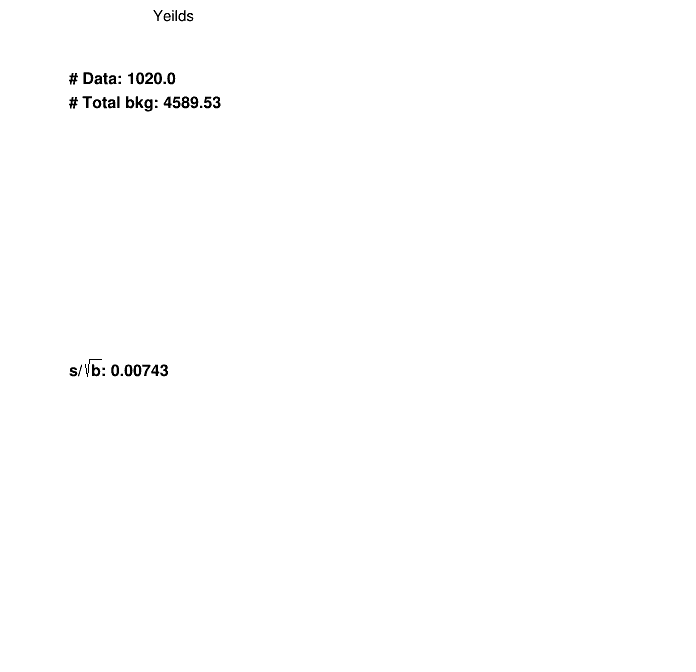

In [33]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [4, 0, 40, "p_{T}(l_{trail}) [GeV]"],
        "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
        "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
        "U_pre": [14, 0, 660, "U [GeV]"],
        "JZB_pre": [14, 80, 660, "JZB"],
        "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
        "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
        "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
        "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
        "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
        "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
        "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [34]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [35]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [36]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)
